# Fathah - PISA 2022 EDA and Data Cleaning

This notebook explores and cleans the PISA 2022 student data for the six education systems used in our project:
UAE, Saudi Arabia, Qatar, Jordan, Morocco and Palestine.

In [ ]:
# Loading the PISA dataset and setting up the environment
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the main project folder
ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "requirements.txt").exists()
)

# Location of the PISA student dataset
student_path = ROOT / "data" / "parquet" / "CY08MSP_STU_QQQ"

print("Project folder:", ROOT)
print("Student data:", student_path)

Project folder: c:\Users\Butler Engineering\Documents\F21DL-PISA-2022
Student data: c:\Users\Butler Engineering\Documents\F21DL-PISA-2022\data\parquet\CY08MSP_STU_QQQ


In [ ]:
# Cleaning the data by loading only the useful columns and filtering for the six countries of interest
countries = ["ARE", "SAU", "QAT", "JOR", "MAR", "PSE"]

columns = [
    "CNT",
    "CNTSTUID",
    "CNTSCHID",
    "W_FSTUWT",
    "ST004D01T",
    "ESCS",
    "ANXMAT",
    "BELONG",
    "BULLIED",
    "FEELSAFE",
    "TEACHSUP",
    "DISCLIM",
    "FAMSUP",
    "ICTDISTR"
]

# Add the 10 maths plausible values
columns += [f"PV{i}MATH" for i in range(1, 11)]

df = pd.read_parquet(student_path, columns=columns)

# Keep only our six systems
df = df[df["CNT"].isin(countries)].copy()

print("Rows:", len(df))
print("Columns:", len(df.columns))

df.head()

Rows: 61775
Columns: 24


,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,ST004D01T,ESCS,ANXMAT,BELONG,BULLIED,FEELSAFE,...,PV1MATH,PV2MATH,PV3MATH,PV4MATH,PV5MATH,PV6MATH,PV7MATH,PV8MATH,PV9MATH,PV10MATH
195281,PSE,27500001.0,27500099.0,1.71257,2.0,-0.6594,NaN,-0.0437,-1.2280,-0.7560,...,419.291,387.304,394.929,456.058,435.678,447.933,437.343,441.194,419.301,412.949
195282,PSE,27500002.0,27500050.0,12.93197,2.0,-0.7512,0.4067,0.3142,-0.1879,0.2435,...,300.023,362.847,384.805,304.533,369.900,328.394,345.006,361.379,296.230,333.500
195283,PSE,27500003.0,27500157.0,10.87162,2.0,-0.7349,0.9050,-1.1019,1.7093,-0.7560,...,292.200,239.644,203.422,251.802,234.985,273.864,261.993,268.537,211.594,233.347
195284,PSE,27500004.0,27500213.0,13.54563,2.0,1.6743,NaN,-0.6206,-0.2670,-0.7560,...,285.349,291.745,319.829,294.893,279.326,254.284,224.396,277.126,315.080,251.803
195285,PSE,27500005.0,27500038.0,6.35577,2.0,-1.7778,0.4290,1.0491,0.4557,0.6942,...,398.140,413.128,425.073,388.359,363.793,408.625,363.831,383.462,422.868,434.154


In [ ]:
# Number of students in each country
df["CNT"].value_counts()

CNT
ARE    24600
PSE     7905
JOR     7799
QAT     7676
SAU     6928
MAR     6867
Name: count, dtype: int64

In [ ]:
# Identifying the missing values
missing = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
      .round(1)
)

missing

ICTDISTR     79.7
FAMSUP       26.2
ANXMAT       22.9
TEACHSUP     18.0
DISCLIM      16.9
BELONG        9.2
BULLIED       9.0
FEELSAFE      8.8
ESCS          3.9
ST004D01T     0.0
CNTSCHID      0.0
W_FSTUWT      0.0
CNT           0.0
CNTSTUID      0.0
PV1MATH       0.0
PV2MATH       0.0
PV3MATH       0.0
PV4MATH       0.0
PV5MATH       0.0
PV6MATH       0.0
PV7MATH       0.0
PV8MATH       0.0
PV9MATH       0.0
PV10MATH      0.0
dtype: float64

In [ ]:
# Finding the amount of duplicated records/students
df["CNTSTUID"].duplicated().sum()

np.int64(0)

In [ ]:
# Gender classification
df["GENDER"] = df["ST004D01T"].map({
    1: "Female",
    2: "Male"
})

df[["ST004D01T", "GENDER"]].head()

,ST004D01T,GENDER
195281,2.0,Male
195282,2.0,Male
195283,2.0,Male
195284,2.0,Male
195285,2.0,Male


In [ ]:
# Checking which predictors affect the math score more
df[
    [
        "ESCS",
        "ANXMAT",
        "BELONG",
        "BULLIED",
        "FEELSAFE",
        "TEACHSUP",
        "DISCLIM",
        "FAMSUP",
        "ICTDISTR"
    ]
].describe().round(2)

,ESCS,ANXMAT,BELONG,BULLIED,FEELSAFE,TEACHSUP,DISCLIM,FAMSUP,ICTDISTR
count,59343.00,47652.00,56061.00,56203.00,56324.00,50635.00,51320.00,45571.00,12515.00
mean,-0.32,0.19,-0.18,-0.12,-0.06,0.26,0.02,-0.00,7.58
std,1.21,1.15,0.93,1.17,1.04,1.20,1.08,1.15,3.95
min,-6.39,-2.39,-3.32,-1.23,-2.79,-2.91,-2.55,-3.06,1.00
25%,-1.07,-0.38,-0.77,-1.23,-0.76,-0.56,-0.70,-0.74,4.00
50%,-0.02,0.19,-0.34,-0.27,0.08,0.15,-0.08,-0.14,8.00
75%,0.58,0.78,0.20,0.74,1.12,1.56,0.76,0.88,10.00
max,5.40,2.64,2.78,4.69,1.17,1.56,1.85,1.97,16.00


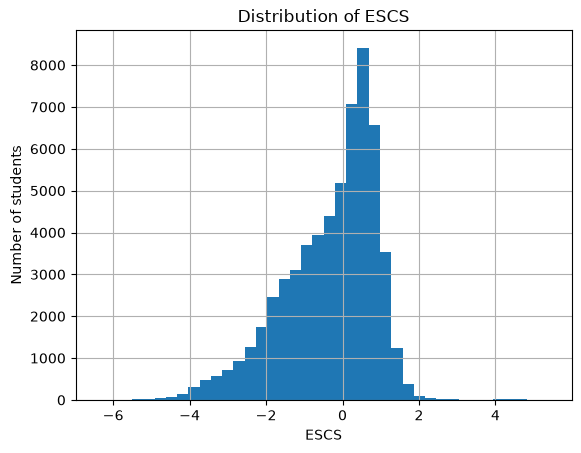

In [ ]:
# Plotting the above visually
df["ESCS"].hist(bins=40)

plt.title("Distribution of ESCS")
plt.xlabel("ESCS")
plt.ylabel("Number of students")

plt.show()

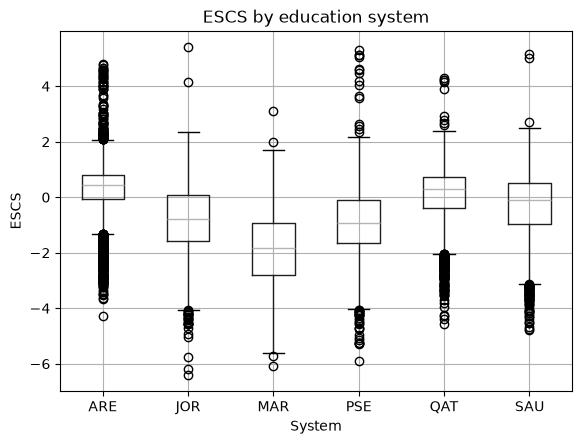

In [ ]:
# Using a boxplot to visualize the distribution of ESCS by education system
df.boxplot(column="ESCS", by="CNT")

plt.title("ESCS by education system")
plt.suptitle("")
plt.xlabel("System")
plt.ylabel("ESCS")

plt.show()

In [ ]:
# Identifying missing values by country
missing_by_country = (
    df.groupby("CNT")
      .apply(lambda x: x.isna().mean() * 100)
      .round(1)
)

missing_by_country[
    [
        "ESCS",
        "ANXMAT",
        "BELONG",
        "BULLIED",
        "FEELSAFE",
        "TEACHSUP",
        "DISCLIM",
        "FAMSUP",
        "ICTDISTR"
    ]
]

,ESCS,ANXMAT,BELONG,BULLIED,FEELSAFE,TEACHSUP,DISCLIM,FAMSUP,ICTDISTR
CNT,,,,,,,,,
ARE,5.7,16.9,9.5,9.2,9.3,14.3,13.6,18.8,100.0
JOR,2.1,28.3,10.7,10.0,9.8,21.8,20.1,32.9,40.7
MAR,0.5,37.4,5.7,5.8,4.8,26.1,23.8,45.2,35.9
PSE,2.6,22.0,9.3,9.1,8.8,17.0,15.9,24.8,100.0
QAT,6.5,30.4,13.0,12.8,12.7,24.8,23.3,34.4,100.0
SAU,2.0,16.1,6.1,6.1,6.0,12.7,12.3,19.0,49.6


ICTDISTR has very high and country-dependent missingness, including 100% missing data in UAE, Palestine and Qatar. It should not be imputed blindly and should be reviewed before inclusion in the shared six-system model. Other predictors such as ANXMAT, FAMSUP, TEACHSUP and DISCLIM also show varying levels of missingness across systems.

In [ ]:
# Identifying complete rows with and without ICTDISTR (highest missing value column)
predictors = [
    "ESCS",
    "ANXMAT",
    "BELONG",
    "BULLIED",
    "FEELSAFE",
    "TEACHSUP",
    "DISCLIM",
    "FAMSUP"
]

print("Total students:", len(df))

complete_without_ict = df[predictors].dropna()
print("Complete rows without ICTDISTR:", len(complete_without_ict))

complete_with_ict = df[predictors + ["ICTDISTR"]].dropna()
print("Complete rows with ICTDISTR:", len(complete_with_ict))

Total students: 61775
Complete rows without ICTDISTR: 43227
Complete rows with ICTDISTR: 9363


Requiring complete data for the selected predictors retains 43,227 of 61,775 students. Including ICTDISTR reduces the usable sample to only 9,363 students because several systems have no ICTDISTR data. Therefore, ICTDISTR is unsuitable for the shared six-system analysis unless an alternative variable is identified.

In [ ]:
# Identifying how many students are left in each country after removing students who are missing any of our selected predictors
complete_by_country = (
    df.dropna(subset=predictors)
      .groupby("CNT")
      .size()
)

complete_by_country

CNT
ARE    19297
JOR     4798
MAR     3399
PSE     5555
QAT     4798
SAU     5380
dtype: int64

In [ ]:
# Percentage of students retained in each country after removing students who are missing any of our selected predictors
original_by_country = df.groupby("CNT").size()

retention = (
    (complete_by_country / original_by_country) * 100
).round(1)

retention

CNT
ARE    78.4
JOR    61.5
MAR    49.5
PSE    70.3
QAT    62.5
SAU    77.7
dtype: float64

Complete-case retention differs across systems. UAE and Saudi Arabia retain about 78% of students, while Morocco retains only 49.5%. This suggests that simply dropping all rows with missing predictor values could affect systems unevenly and potentially bias the final six-system analysis.

In [ ]:
# Finding the estimated average maths performance in each of our six systems
pv_cols = [f"PV{i}MATH" for i in range(1, 11)]

math_by_country = {}

for country, group in df.groupby("CNT"):

    pv_means = []

    for pv in pv_cols:
        mean_score = np.average(
            group[pv],
            weights=group["W_FSTUWT"]
        )

        pv_means.append(mean_score)

    math_by_country[country] = np.mean(pv_means)

math_by_country = pd.Series(math_by_country).round(1)

math_by_country.sort_values(ascending=False)

ARE    431.1
QAT    414.1
SAU    388.8
PSE    365.7
MAR    364.8
JOR    361.2
dtype: float64

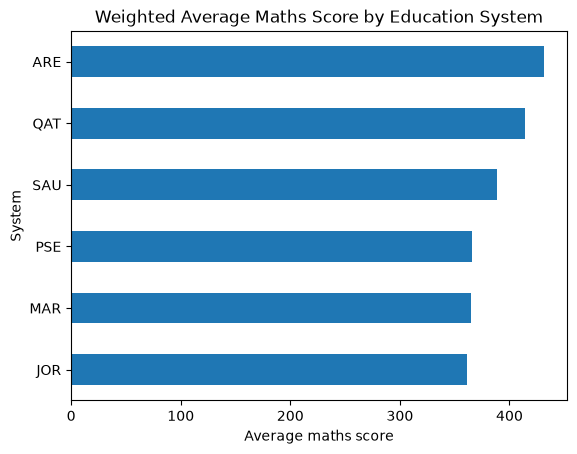

In [ ]:
# Plotting the above visually
math_by_country.sort_values().plot(kind="barh")

plt.title("Weighted Average Maths Score by Education System")
plt.xlabel("Average maths score")
plt.ylabel("System")

plt.show()

Among the six selected systems, the UAE has the highest weighted average mathematics score, followed by Qatar. Jordan, Morocco and Palestine have the lowest average scores, while Saudi Arabia lies between these groups.

In [ ]:
# Identifying the percentage of students in each of our six systems are below maths Level 2
LEVEL2_MATH = 420.07

low_perf_by_country = {}

for country, group in df.groupby("CNT"):

    low_rates = []

    for pv in pv_cols:
        is_low = group[pv] < LEVEL2_MATH

        weighted_rate = np.average(
            is_low,
            weights=group["W_FSTUWT"]
        ) * 100

        low_rates.append(weighted_rate)

    low_perf_by_country[country] = np.mean(low_rates)

low_perf_by_country = pd.Series(low_perf_by_country).round(1)

low_perf_by_country.sort_values()

ARE    49.0
QAT    56.5
SAU    70.0
PSE    79.9
MAR    81.6
JOR    82.8
dtype: float64

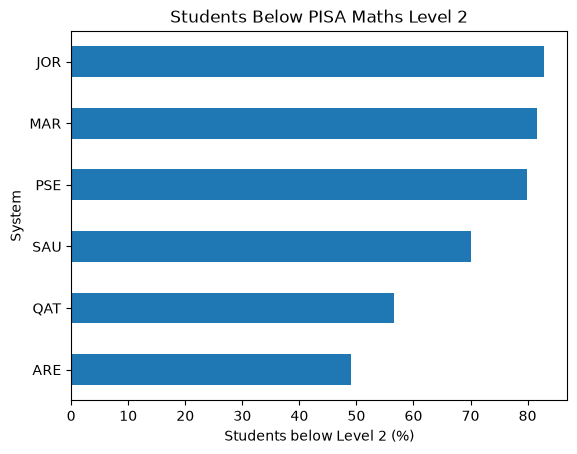

In [ ]:
# Plotting the above visually
low_perf_by_country.sort_values().plot(kind="barh")

plt.title("Students Below PISA Maths Level 2")
plt.xlabel("Students below Level 2 (%)")
plt.ylabel("System")

plt.show()

The UAE has the lowest share of students below PISA Mathematics Level 2 among the six selected systems, at approximately 49%. Jordan has the highest share at approximately 82.8%. Low-performance rates are high across all six systems.

In [ ]:
# Identifying how the predictors affect the maths score 
predictor_vars = [
    "ESCS",
    "ANXMAT",
    "BELONG",
    "BULLIED",
    "FEELSAFE",
    "TEACHSUP",
    "DISCLIM",
    "FAMSUP"
]

associations = {}

for var in predictor_vars:

    country_slopes = []

    for country, group in df.groupby("CNT"):

        clean = group[[var, "W_FSTUWT"] + pv_cols].dropna()

        if len(clean) == 0:
            continue

        pv_slopes = []

        for pv in pv_cols:

            x = clean[var].to_numpy()
            y = clean[pv].to_numpy()
            w = clean["W_FSTUWT"].to_numpy()

            x_mean = np.average(x, weights=w)
            y_mean = np.average(y, weights=w)

            slope = (
                np.sum(w * (x - x_mean) * (y - y_mean))
                / np.sum(w * (x - x_mean) ** 2)
            )

            pv_slopes.append(slope)

        country_slopes.append(np.mean(pv_slopes))

    associations[var] = np.mean(country_slopes)

associations = pd.Series(associations).sort_values()

associations.round(1)

ANXMAT     -13.4
BULLIED    -10.9
TEACHSUP     4.3
FAMSUP       9.4
FEELSAFE    10.0
BELONG      10.7
DISCLIM     12.2
ESCS        21.2
dtype: float64

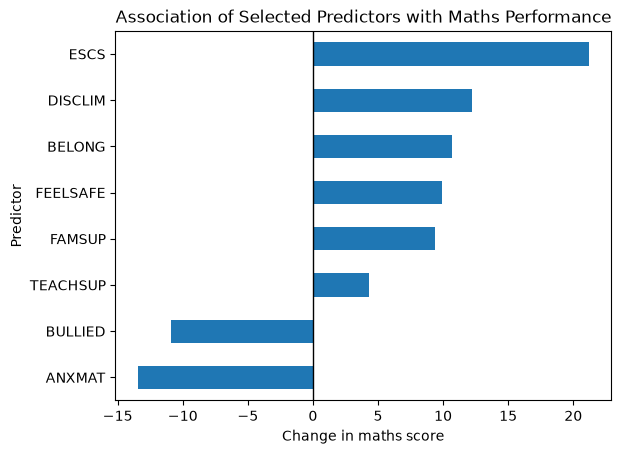

In [ ]:
# Plotting the above visually
associations.plot(kind="barh")

plt.title("Association of Selected Predictors with Maths Performance")
plt.xlabel("Change in maths score")
plt.ylabel("Predictor")

plt.axvline(0, color="black", linewidth=1)

plt.show()

Among the selected predictors, ESCS shows the strongest positive association with mathematics performance, while mathematics anxiety and bullying show negative associations. These relationships are associations and should not be interpreted as causal effects.